# DQN on Atari Bowling: Experimentation by Alain

**Game:** Bowling (`ALE/Bowling-v5`). The agent rolls a ball over 10 frames and scores one point per pin knocked down. Random play scores about 23 per game.

Every experiment cell runs the same four commands from our repo:

| Command | What it does |
| --- | --- |
| `uv run train.py ...` | Trains the agent with the given hyperparameters and prints every game |
| `uv run summary.py ...` | Prints the average reward and best game |
| `uv run plot_results.py ...` | Saves the training plot (rewards, episode length, steps) |
| `uv run greedy_check.py ...` | Plays the saved model like `play.py` (no random moves) and counts the buttons it presses |

## 1. Set up
Installs uv, downloads our code from GitHub and installs the packages from `uv.lock`. Also it checks GPU availability.

In [1]:
import os

from IPython.display import Image

!curl -LsSf https://astral.sh/uv/install.sh | sh
os.environ["PATH"] = os.path.expanduser("~/.local/bin") + ":" + os.environ["PATH"]
os.environ["UV_PROJECT_ENVIRONMENT"] = "/root/dqn-venv" # keep the packages out of the saved output
os.environ["PYTHONUNBUFFERED"] = "1" # show each game as soon as it finishes
os.environ.pop("MPLBACKEND", None) # let plot_results.py save its PNG files normally

!git clone -q https://github.com/ai-ngabo/bowling-env_deep-q-learning.git /kaggle/working/repo
%cd /kaggle/working/repo
!uv sync -q
!uv run python -c "import torch; print('GPU available:', torch.cuda.is_available())"

downloading uv 0.13.8 x86_64-unknown-linux-gnu
installing to /usr/local/bin
  uv
  uvx
everything's installed!
/kaggle/working/repo
GPU available: True


## 2. Experiments
Exps **1–7** change one hyperparameter at a time compared with the baseline (Exp 1), so each difference can be measured. Exps **8–10** combine the changes that helped.

| Hyperparameter | What it controls | Too low | Too high |
| --- | --- | --- | --- |
| `--lr` | Size of each update to the network | Learns slowly | Unstable: forgets what it learned |
| `--gamma` | How far ahead the agent looks (about 1 / (1 - gamma) steps) | Short-sighted | Slower, noisier learning |
| `--batch-size` | Saved moves used in each update | Noisy updates | Smoother, but slower updates |
| `--eps-start` | How random the agent is at the beginning | Explores too little at first | 1.0 = fully random |
| `--eps-end` | Random moves kept until the end | Can get stuck in one habit | Random moves spoil good throws |
| `--eps-decay` | Steps to go from eps-start to eps-end | Stops exploring too early | Wastes time exploring |

**After each experiment, look at:**
- the **summary**: average reward (random play is about 23),
- the **plot**: does the 10-game average rise and stay up, or rise and fall back? Does the episode length stay around 2,100 steps?
- the **greedy check**: what the model does in `play.py`. One button at 100% is a fixed trick; "never finished the game" means it doesn't throw.

### Experiment 1
Baseline: standard DQN values for Atari

Device: cuda
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Episode    1 | steps    2126 | len  2126 | reward    20.0 | eps 0.980
Episode    2 | steps    4257 | len  2131 | reward    28.0 | eps 0.960
Episode    3 | steps    6373 | len  2116 | reward    34.0 | eps 0.939
Episode    4 | steps    8498 | len  2125 | reward    24.0 | eps 0.919
Episode    5 | steps   10618 | len  2120 | reward    27.0 | eps 0.899
Episode    6 | steps   12727 | len  2109 | reward    29.0 | eps 0.879
Episode    7 | steps   14841 | len  2114 | reward    27.0 | eps 0.859
Episode    8 | steps   16939 | len  2098 | reward    30.0 | eps 0.839
Episode    9 | steps   19066 | len  2127 | reward    20.0 | eps 0.819
Episode   10 | steps   21178 | len  2112 | reward    24.0 | eps 0.799
Episode   11 | steps   23262 | len  2084 | reward    18.0 | eps 0.779
Episode   12 | steps   25367 | len  2105 | reward    22.0 | eps 0.759
Episode   13 | steps   27499 | len  2132 | reward    27.0 | eps 0.7

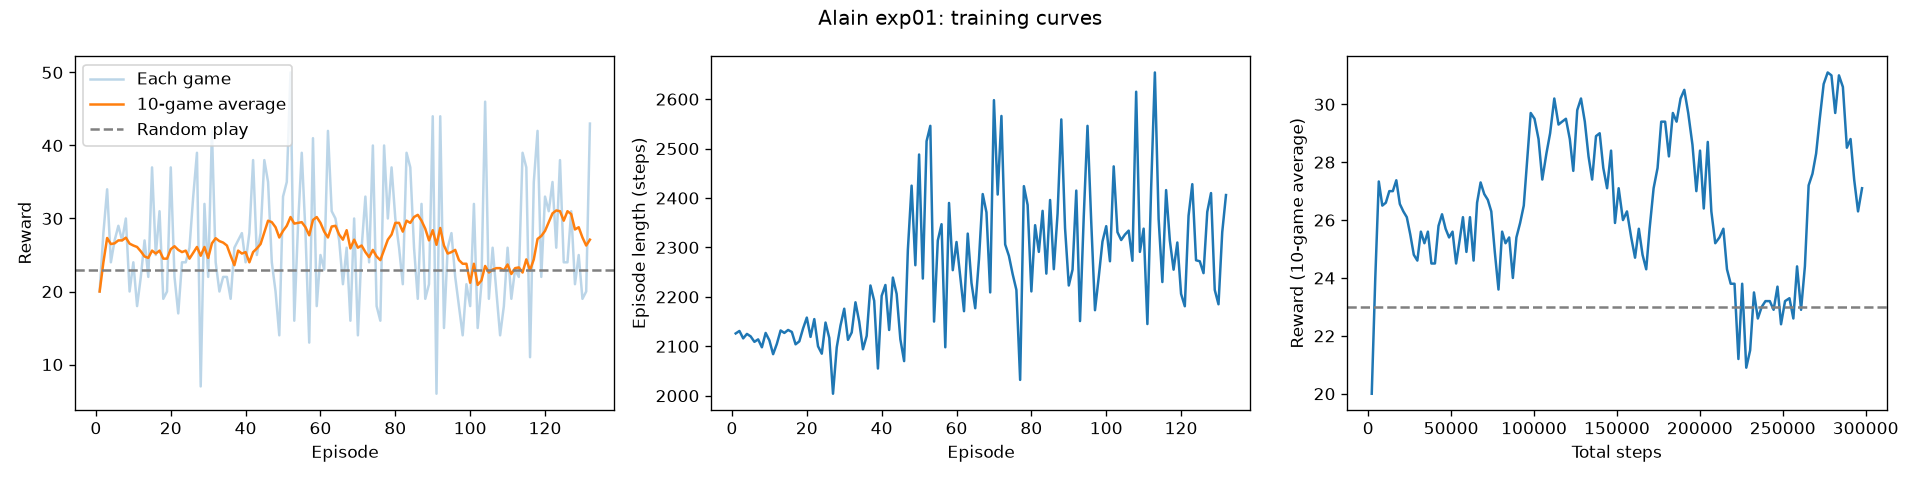

In [2]:
!uv run train.py --member Alain --exp 1 --lr 1e-4 --gamma 0.99 --batch-size 32 --eps-start 1.0 --eps-end 0.05 --eps-decay 100000
!uv run summary.py --member Alain --exp 1
!uv run plot_results.py --member Alain --exp 1
!uv run greedy_check.py --member Alain --exp 1 --games 3
!zip -qr /kaggle/working/Alain_progress.zip Alain
Image("Alain/exp01/training_plot.png")

### Experiment 2
Lower learning rate (0.00001): slower but steadier?

Device: cuda
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Episode    1 | steps    2126 | len  2126 | reward    20.0 | eps 0.980
Episode    2 | steps    4257 | len  2131 | reward    28.0 | eps 0.960
Episode    3 | steps    6373 | len  2116 | reward    34.0 | eps 0.939
Episode    4 | steps    8498 | len  2125 | reward    24.0 | eps 0.919
Episode    5 | steps   10618 | len  2120 | reward    27.0 | eps 0.899
Episode    6 | steps   12727 | len  2109 | reward    26.0 | eps 0.879
Episode    7 | steps   14841 | len  2114 | reward    27.0 | eps 0.859
Episode    8 | steps   16971 | len  2130 | reward    28.0 | eps 0.839
Episode    9 | steps   19087 | len  2116 | reward    17.0 | eps 0.819
Episode   10 | steps   21181 | len  2094 | reward    21.0 | eps 0.799
Episode   11 | steps   23285 | len  2104 | reward    28.0 | eps 0.779
Episode   12 | steps   25400 | len  2115 | reward    24.0 | eps 0.759
Episode   13 | steps   27500 | len  2100 | reward    19.0 | eps 0.7

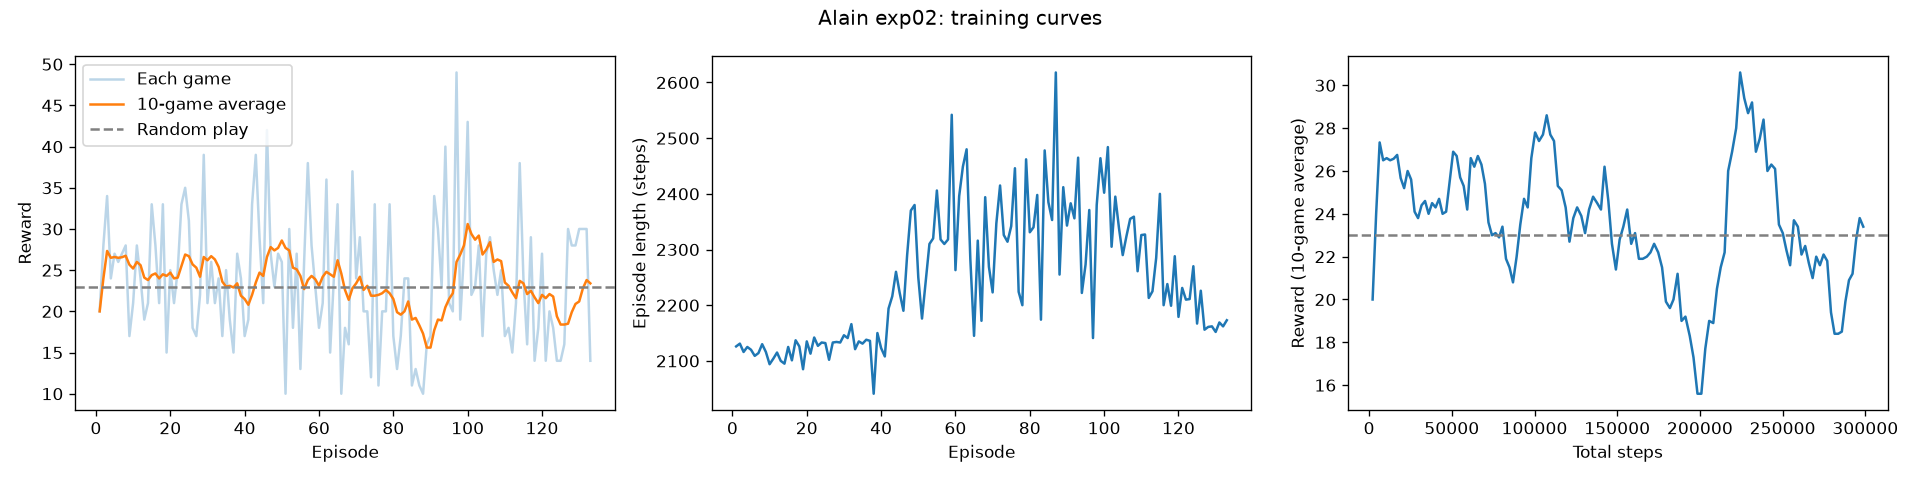

In [3]:
!uv run train.py --member Alain --exp 2 --lr 1e-5 --gamma 0.99 --batch-size 32 --eps-start 1.0 --eps-end 0.05 --eps-decay 100000
!uv run summary.py --member Alain --exp 2
!uv run plot_results.py --member Alain --exp 2
!uv run greedy_check.py --member Alain --exp 2 --games 3
!zip -qr /kaggle/working/Alain_progress.zip Alain
Image("Alain/exp02/training_plot.png")

### Experiment 3
Higher learning rate (0.0005): faster, or unstable?

Device: cuda
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Episode    1 | steps    2126 | len  2126 | reward    20.0 | eps 0.980
Episode    2 | steps    4257 | len  2131 | reward    28.0 | eps 0.960
Episode    3 | steps    6373 | len  2116 | reward    34.0 | eps 0.939
Episode    4 | steps    8498 | len  2125 | reward    24.0 | eps 0.919
Episode    5 | steps   10618 | len  2120 | reward    27.0 | eps 0.899
Episode    6 | steps   12727 | len  2109 | reward    29.0 | eps 0.879
Episode    7 | steps   14841 | len  2114 | reward    27.0 | eps 0.859
Episode    8 | steps   16943 | len  2102 | reward    25.0 | eps 0.839
Episode    9 | steps   19066 | len  2123 | reward    18.0 | eps 0.819
Episode   10 | steps   21186 | len  2120 | reward    33.0 | eps 0.799
Episode   11 | steps   23305 | len  2119 | reward    15.0 | eps 0.779
Episode   12 | steps   25400 | len  2095 | reward    14.0 | eps 0.759
Episode   13 | steps   27524 | len  2124 | reward    31.0 | eps 0.7

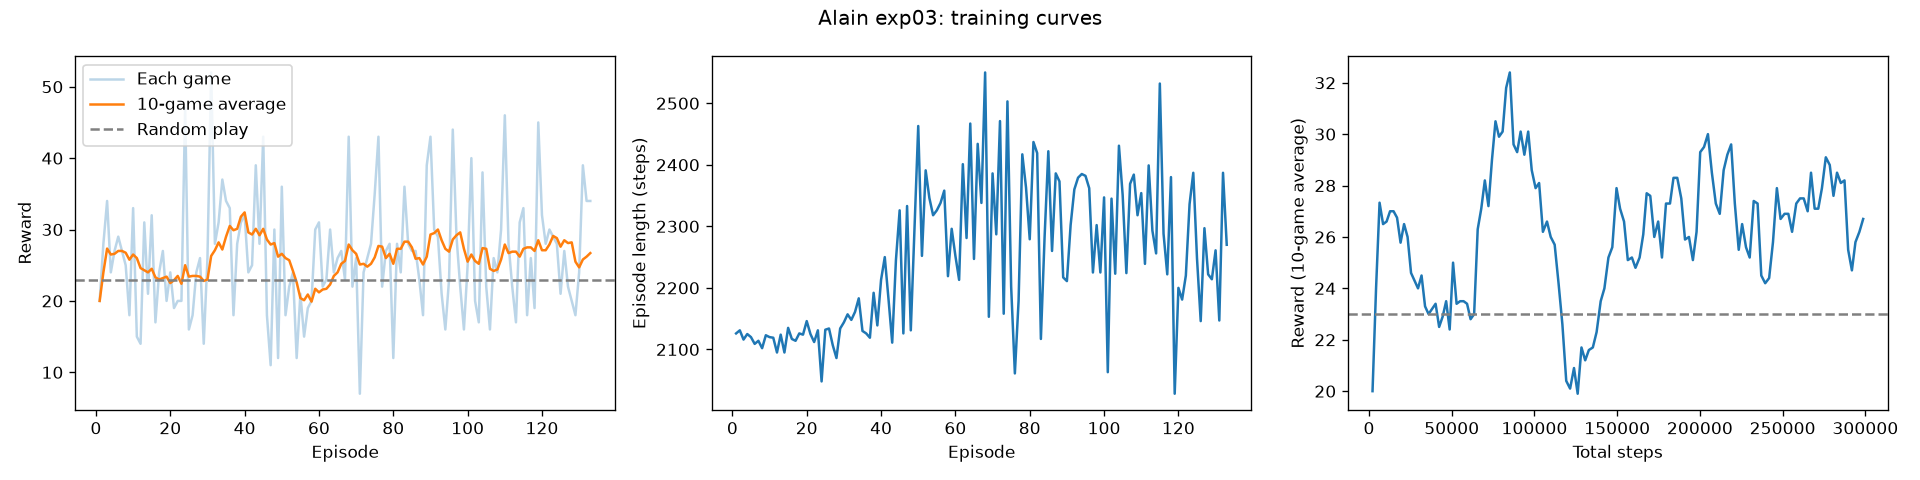

In [4]:
!uv run train.py --member Alain --exp 3 --lr 5e-4 --gamma 0.99 --batch-size 32 --eps-start 1.0 --eps-end 0.05 --eps-decay 100000
!uv run summary.py --member Alain --exp 3
!uv run plot_results.py --member Alain --exp 3
!uv run greedy_check.py --member Alain --exp 3 --games 3
!zip -qr /kaggle/working/Alain_progress.zip Alain
Image("Alain/exp03/training_plot.png")

### Experiment 4
Smaller batch (16): noisier updates?

Device: cuda
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Episode    1 | steps    2126 | len  2126 | reward    20.0 | eps 0.980
Episode    2 | steps    4257 | len  2131 | reward    28.0 | eps 0.960
Episode    3 | steps    6373 | len  2116 | reward    34.0 | eps 0.939
Episode    4 | steps    8498 | len  2125 | reward    24.0 | eps 0.919
Episode    5 | steps   10603 | len  2105 | reward    27.0 | eps 0.899
Episode    6 | steps   12733 | len  2130 | reward    24.0 | eps 0.879
Episode    7 | steps   14851 | len  2118 | reward    21.0 | eps 0.859
Episode    8 | steps   16949 | len  2098 | reward    21.0 | eps 0.839
Episode    9 | steps   19069 | len  2120 | reward    31.0 | eps 0.819
Episode   10 | steps   21129 | len  2060 | reward    18.0 | eps 0.799
Episode   11 | steps   23234 | len  2105 | reward    21.0 | eps 0.779
Episode   12 | steps   25343 | len  2109 | reward    14.0 | eps 0.759
Episode   13 | steps   27475 | len  2132 | reward    30.0 | eps 0.7

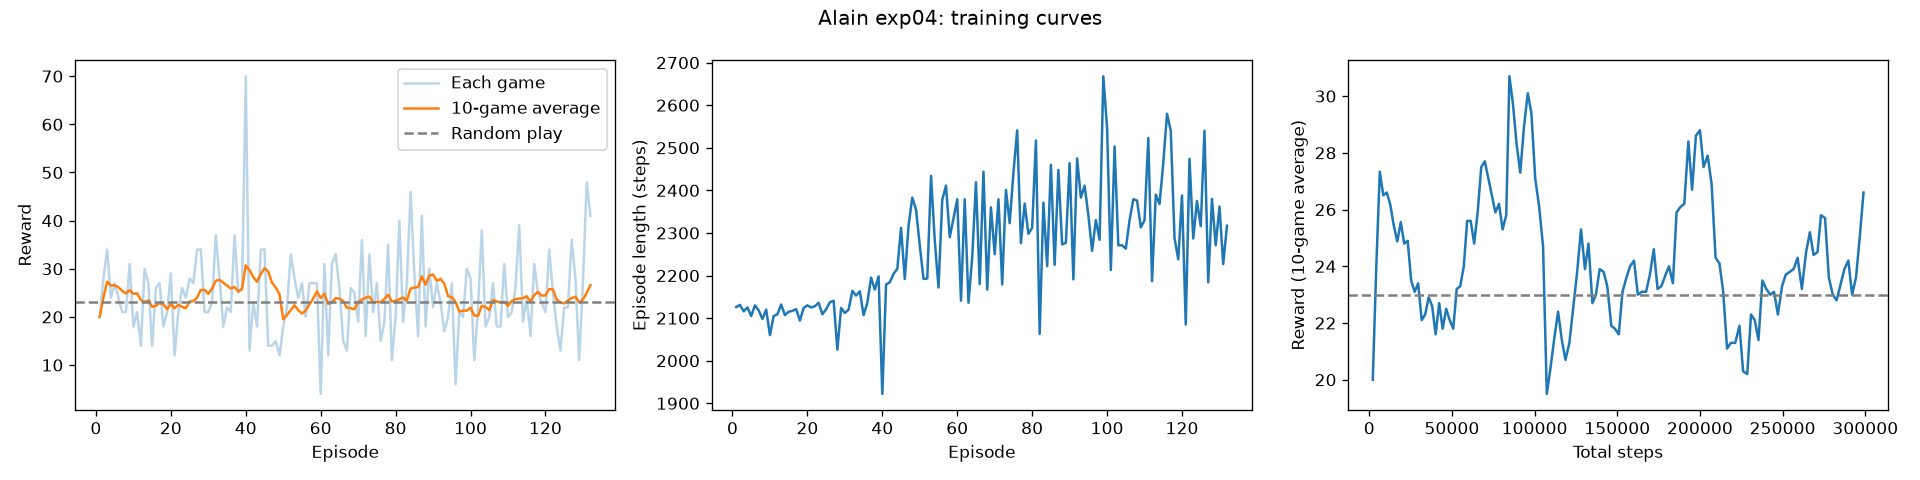

In [5]:
!uv run train.py --member Alain --exp 4 --lr 1e-4 --gamma 0.99 --batch-size 16 --eps-start 1.0 --eps-end 0.05 --eps-decay 100000
!uv run summary.py --member Alain --exp 4
!uv run plot_results.py --member Alain --exp 4
!uv run greedy_check.py --member Alain --exp 4 --games 3
!zip -qr /kaggle/working/Alain_progress.zip Alain
Image("Alain/exp04/training_plot.png")

### Experiment 5
Bigger batch (64): smoother updates?

Device: cuda
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Episode    1 | steps    2126 | len  2126 | reward    20.0 | eps 0.980
Episode    2 | steps    4257 | len  2131 | reward    28.0 | eps 0.960
Episode    3 | steps    6373 | len  2116 | reward    34.0 | eps 0.939
Episode    4 | steps    8498 | len  2125 | reward    24.0 | eps 0.919
Episode    5 | steps   10606 | len  2108 | reward    27.0 | eps 0.899
Episode    6 | steps   12704 | len  2098 | reward    27.0 | eps 0.879
Episode    7 | steps   14830 | len  2126 | reward    31.0 | eps 0.859
Episode    8 | steps   16944 | len  2114 | reward    31.0 | eps 0.839
Episode    9 | steps   19067 | len  2123 | reward    27.0 | eps 0.819
Episode   10 | steps   21155 | len  2088 | reward    18.0 | eps 0.799
Episode   11 | steps   23256 | len  2101 | reward    21.0 | eps 0.779
Episode   12 | steps   25373 | len  2117 | reward    27.0 | eps 0.759
Episode   13 | steps   27505 | len  2132 | reward    27.0 | eps 0.7

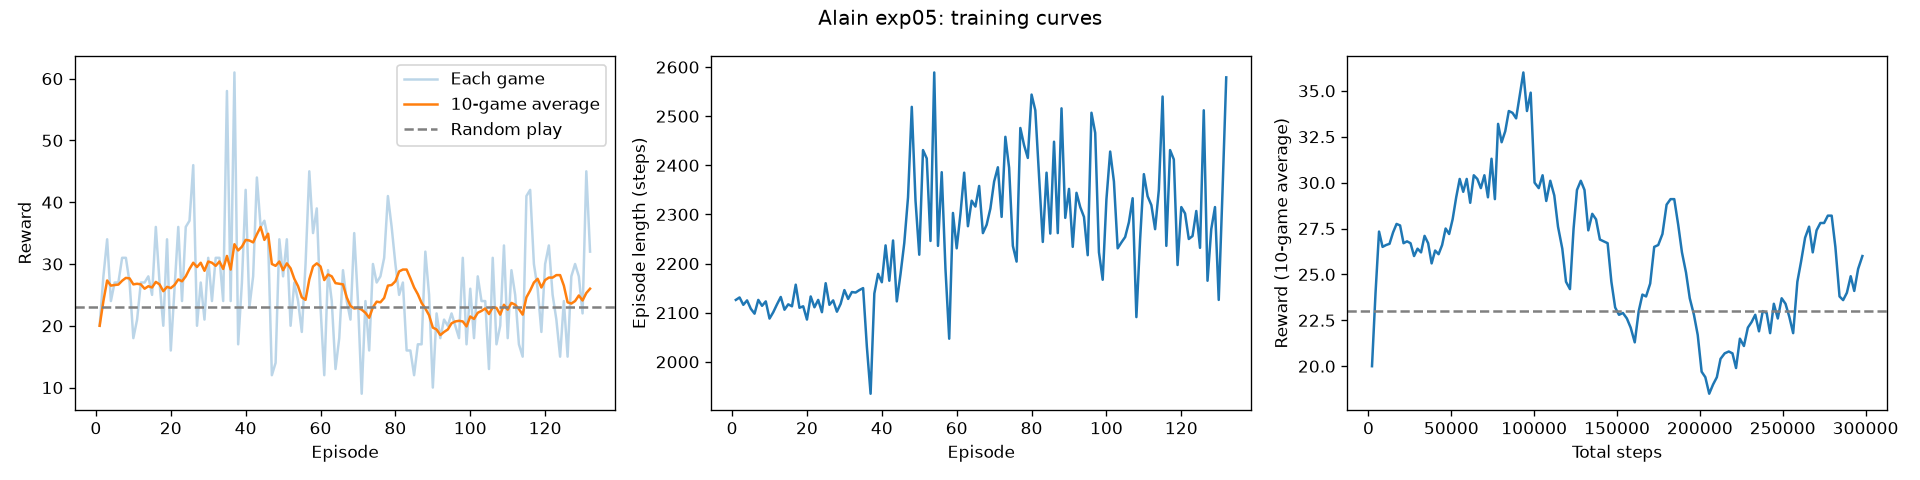

In [2]:
!uv run train.py --member Alain --exp 5 --lr 1e-4 --gamma 0.99 --batch-size 64 --eps-start 1.0 --eps-end 0.05 --eps-decay 100000
!uv run summary.py --member Alain --exp 5
!uv run plot_results.py --member Alain --exp 5
!uv run greedy_check.py --member Alain --exp 5 --games 3
!zip -qr /kaggle/working/Alain_progress.zip Alain
Image("Alain/exp05/training_plot.png")

### Experiment 6
Lower gamma (0.95): looks about 20 steps ahead instead of 100

Device: cuda
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Episode    1 | steps    2126 | len  2126 | reward    20.0 | eps 0.980
Episode    2 | steps    4257 | len  2131 | reward    28.0 | eps 0.960
Episode    3 | steps    6373 | len  2116 | reward    34.0 | eps 0.939
Episode    4 | steps    8498 | len  2125 | reward    24.0 | eps 0.919
Episode    5 | steps   10618 | len  2120 | reward    27.0 | eps 0.899
Episode    6 | steps   12727 | len  2109 | reward    29.0 | eps 0.879
Episode    7 | steps   14841 | len  2114 | reward    27.0 | eps 0.859
Episode    8 | steps   16939 | len  2098 | reward    30.0 | eps 0.839
Episode    9 | steps   19066 | len  2127 | reward    20.0 | eps 0.819
Episode   10 | steps   21178 | len  2112 | reward    27.0 | eps 0.799
Episode   11 | steps   23249 | len  2071 | reward    12.0 | eps 0.779
Episode   12 | steps   25380 | len  2131 | reward    30.0 | eps 0.759
Episode   13 | steps   27487 | len  2107 | reward    19.0 | eps 0.7

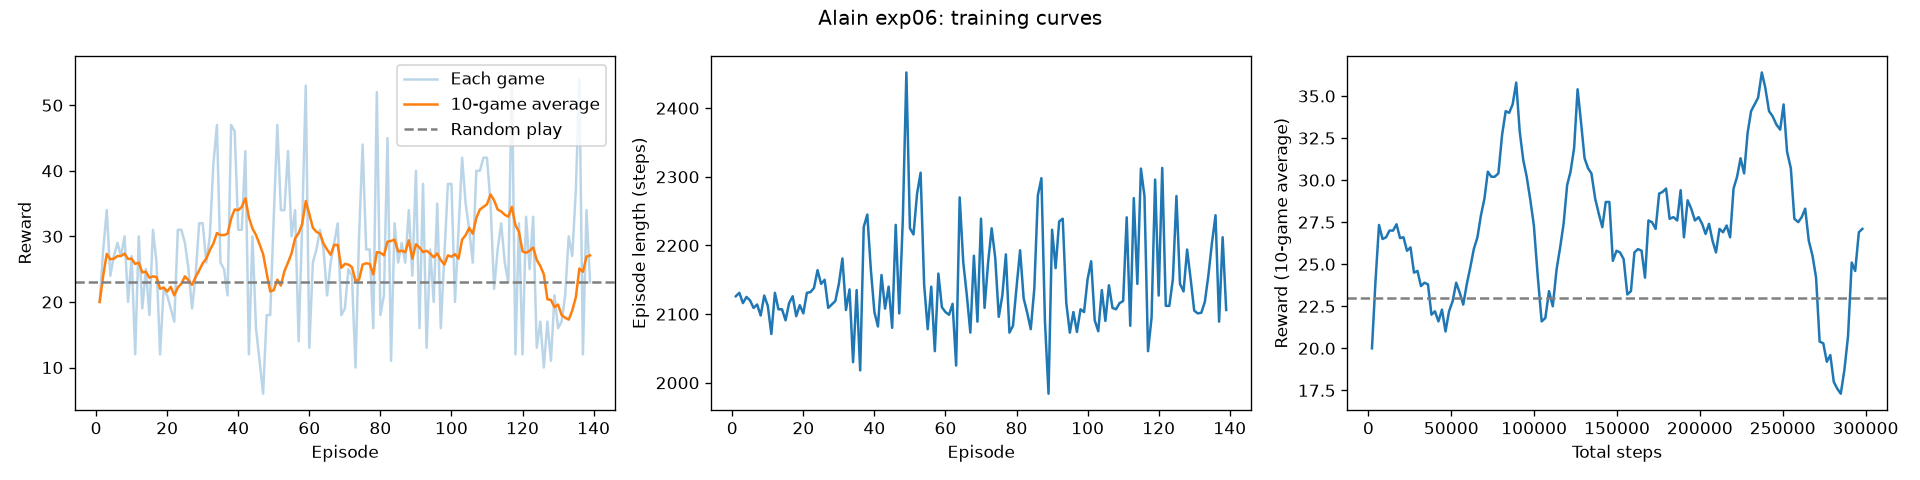

In [3]:
!uv run train.py --member Alain --exp 6 --lr 1e-4 --gamma 0.95 --batch-size 32 --eps-start 1.0 --eps-end 0.05 --eps-decay 100000
!uv run summary.py --member Alain --exp 6
!uv run plot_results.py --member Alain --exp 6
!uv run greedy_check.py --member Alain --exp 6 --games 3
!zip -qr /kaggle/working/Alain_progress.zip Alain
Image("Alain/exp06/training_plot.png")

### Experiment 7
Higher gamma (0.995): looks about 200 steps ahead

Device: cuda
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Episode    1 | steps    2126 | len  2126 | reward    20.0 | eps 0.980
Episode    2 | steps    4257 | len  2131 | reward    28.0 | eps 0.960
Episode    3 | steps    6373 | len  2116 | reward    34.0 | eps 0.939
Episode    4 | steps    8498 | len  2125 | reward    24.0 | eps 0.919
Episode    5 | steps   10618 | len  2120 | reward    27.0 | eps 0.899
Episode    6 | steps   12727 | len  2109 | reward    29.0 | eps 0.879
Episode    7 | steps   14841 | len  2114 | reward    27.0 | eps 0.859
Episode    8 | steps   16971 | len  2130 | reward    28.0 | eps 0.839
Episode    9 | steps   19083 | len  2112 | reward    24.0 | eps 0.819
Episode   10 | steps   21181 | len  2098 | reward    21.0 | eps 0.799
Episode   11 | steps   23285 | len  2104 | reward    25.0 | eps 0.779
Episode   12 | steps   25400 | len  2115 | reward    22.0 | eps 0.759
Episode   13 | steps   27500 | len  2100 | reward    25.0 | eps 0.7

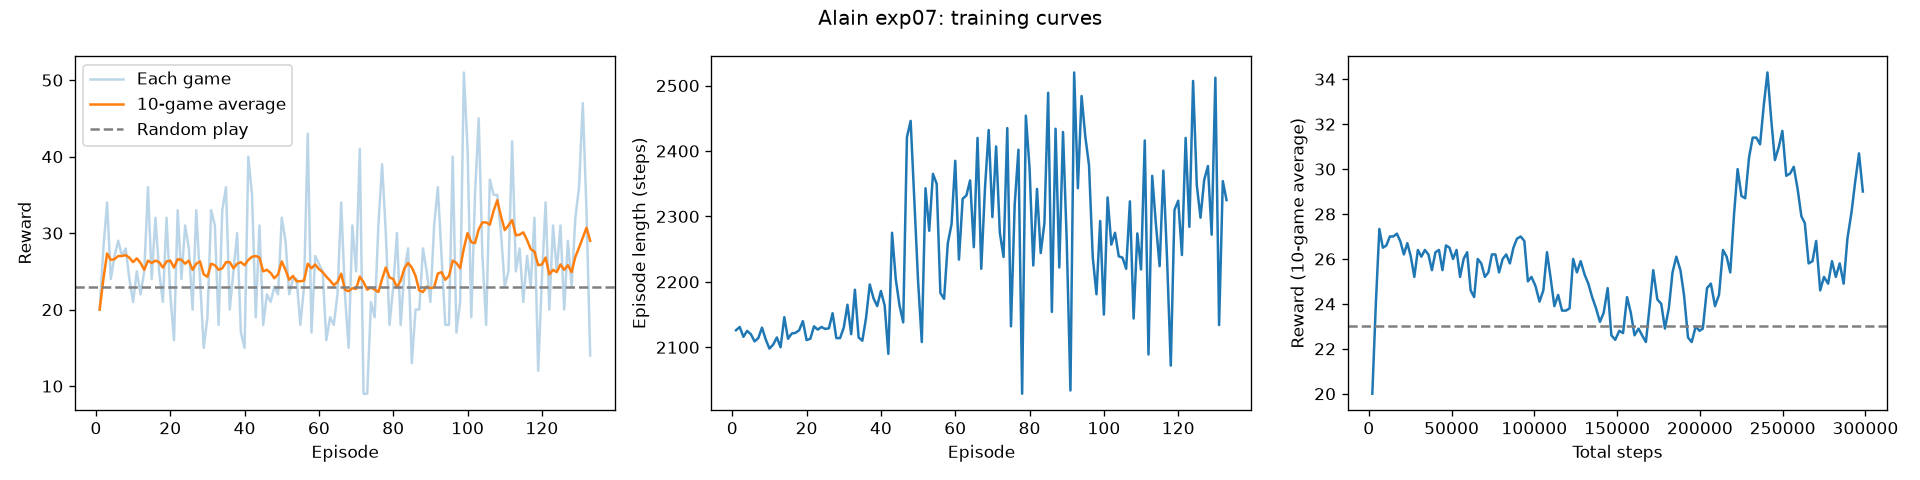

In [4]:
!uv run train.py --member Alain --exp 7 --lr 1e-4 --gamma 0.995 --batch-size 32 --eps-start 1.0 --eps-end 0.05 --eps-decay 100000
!uv run summary.py --member Alain --exp 7
!uv run plot_results.py --member Alain --exp 7
!uv run greedy_check.py --member Alain --exp 7 --games 3
!zip -qr /kaggle/working/Alain_progress.zip Alain
Image("Alain/exp07/training_plot.png")

### Experiment 8
Combine the two best single changes: batch 64 (Exp 5) + gamma 0.95 (Exp 6)

Device: cuda
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Episode    1 | steps    2126 | len  2126 | reward    20.0 | eps 0.980
Episode    2 | steps    4257 | len  2131 | reward    28.0 | eps 0.960
Episode    3 | steps    6373 | len  2116 | reward    34.0 | eps 0.939
Episode    4 | steps    8498 | len  2125 | reward    24.0 | eps 0.919
Episode    5 | steps   10606 | len  2108 | reward    27.0 | eps 0.899
Episode    6 | steps   12707 | len  2101 | reward    24.0 | eps 0.879
Episode    7 | steps   14805 | len  2098 | reward    25.0 | eps 0.859
Episode    8 | steps   16895 | len  2090 | reward    18.0 | eps 0.839
Episode    9 | steps   18975 | len  2080 | reward    21.0 | eps 0.820
Episode   10 | steps   21127 | len  2152 | reward    36.0 | eps 0.799
Episode   11 | steps   23260 | len  2133 | reward    27.0 | eps 0.779
Episode   12 | steps   25387 | len  2127 | reward    30.0 | eps 0.759
Episode   13 | steps   27402 | len  2015 | reward    32.0 | eps 0.7

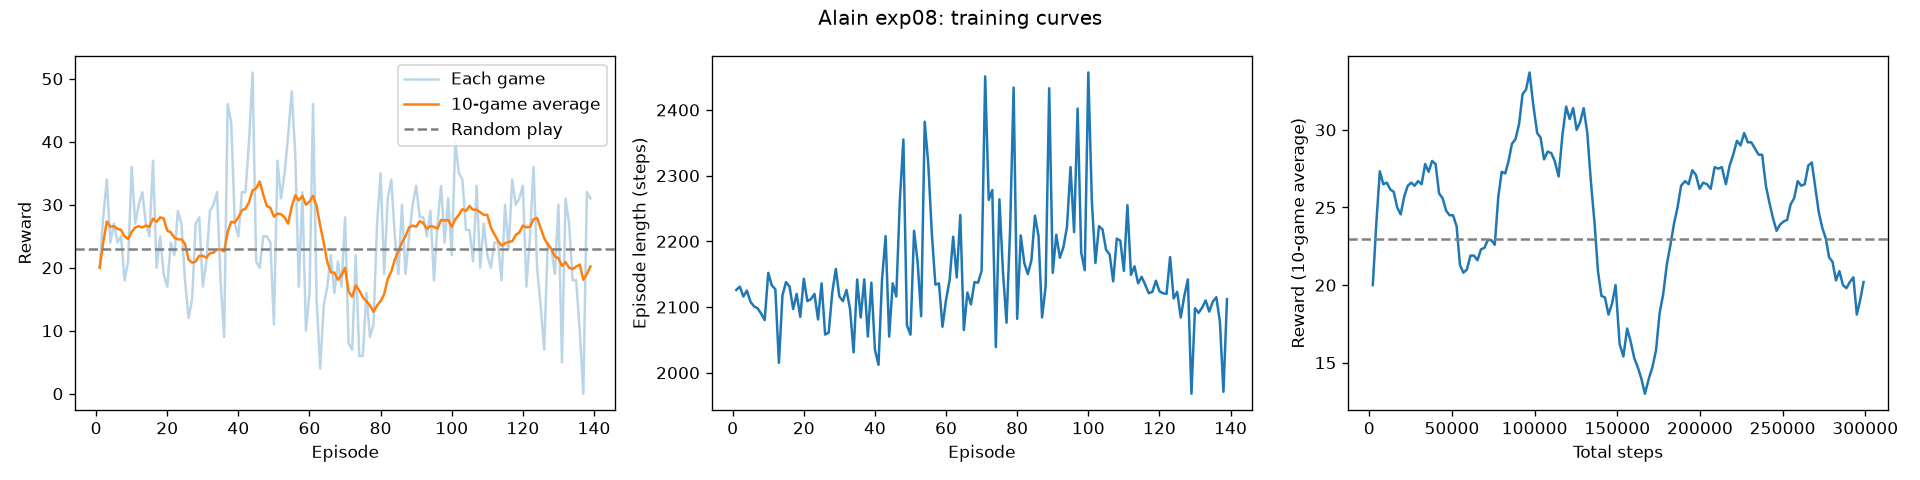

In [6]:
!uv run train.py --member Alain --exp 8 --lr 1e-4 --gamma 0.95 --batch-size 64 --eps-start 1.0 --eps-end 0.05 --eps-decay 100000
!uv run summary.py --member Alain --exp 8
!uv run plot_results.py --member Alain --exp 8
!uv run greedy_check.py --member Alain --exp 8 --games 3
!zip -qr /kaggle/working/Alain_progress.zip Alain
Image("Alain/exp08/training_plot.png")

### Experiment 9
Batch 64 + slower epsilon decay (200,000): does exploring longer stop the drop?

Device: cuda
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Episode    1 | steps    2101 | len  2101 | reward    19.0 | eps 0.990
Episode    2 | steps    4234 | len  2133 | reward    28.0 | eps 0.980
Episode    3 | steps    6342 | len  2108 | reward    25.0 | eps 0.970
Episode    4 | steps    8435 | len  2093 | reward    21.0 | eps 0.960
Episode    5 | steps   10533 | len  2098 | reward    22.0 | eps 0.950
Episode    6 | steps   12634 | len  2101 | reward    14.0 | eps 0.940
Episode    7 | steps   14751 | len  2117 | reward    27.0 | eps 0.930
Episode    8 | steps   16846 | len  2095 | reward    13.0 | eps 0.920
Episode    9 | steps   18953 | len  2107 | reward    21.0 | eps 0.910
Episode   10 | steps   21075 | len  2122 | reward    23.0 | eps 0.900
Episode   11 | steps   23192 | len  2117 | reward    27.0 | eps 0.890
Episode   12 | steps   25311 | len  2119 | reward    22.0 | eps 0.880
Episode   13 | steps   27431 | len  2120 | reward    26.0 | eps 0.8

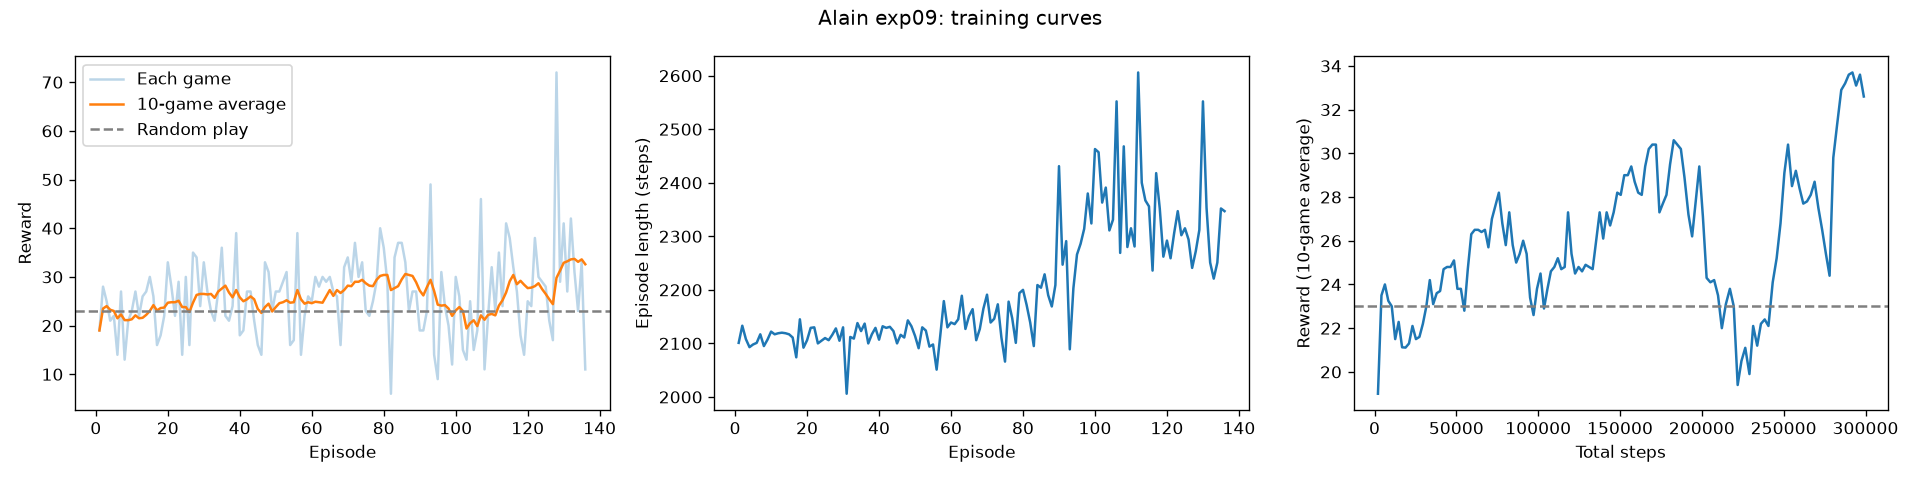

In [7]:
!uv run train.py --member Alain --exp 9 --lr 1e-4 --gamma 0.99 --batch-size 64 --eps-start 1.0 --eps-end 0.05 --eps-decay 200000
!uv run summary.py --member Alain --exp 9
!uv run plot_results.py --member Alain --exp 9
!uv run greedy_check.py --member Alain --exp 9 --games 3
!zip -qr /kaggle/working/Alain_progress.zip Alain
Image("Alain/exp09/training_plot.png")

### Experiment 10
Calmer updates (lr 0.00005 + batch 64) with Exp 9’s slower decay: can the final model stay stable?

Device: cuda
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Episode    1 | steps    2101 | len  2101 | reward    19.0 | eps 0.990
Episode    2 | steps    4234 | len  2133 | reward    28.0 | eps 0.980
Episode    3 | steps    6342 | len  2108 | reward    25.0 | eps 0.970
Episode    4 | steps    8435 | len  2093 | reward    21.0 | eps 0.960
Episode    5 | steps   10533 | len  2098 | reward    22.0 | eps 0.950
Episode    6 | steps   12634 | len  2101 | reward    14.0 | eps 0.940
Episode    7 | steps   14751 | len  2117 | reward    27.0 | eps 0.930
Episode    8 | steps   16846 | len  2095 | reward    13.0 | eps 0.920
Episode    9 | steps   18953 | len  2107 | reward    21.0 | eps 0.910
Episode   10 | steps   21075 | len  2122 | reward    23.0 | eps 0.900
Episode   11 | steps   23192 | len  2117 | reward    27.0 | eps 0.890
Episode   12 | steps   25311 | len  2119 | reward    22.0 | eps 0.880
Episode   13 | steps   27431 | len  2120 | reward    26.0 | eps 0.8

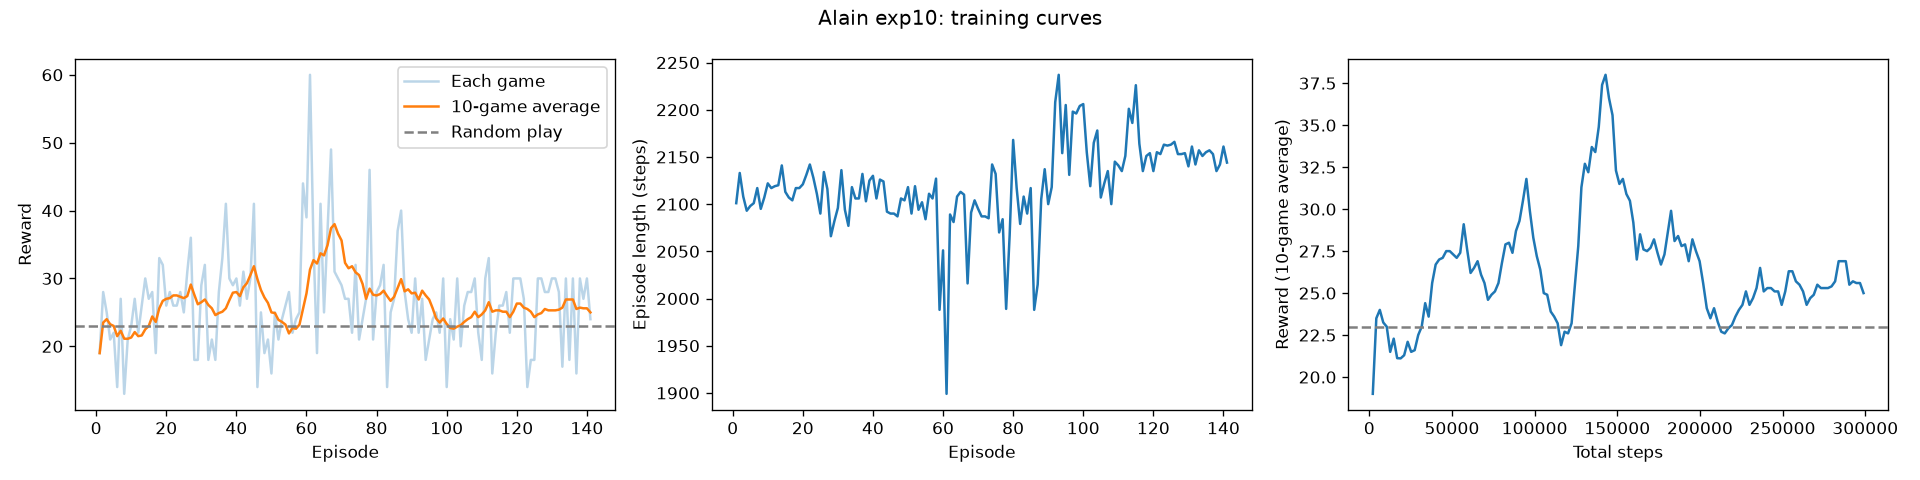

In [8]:
!uv run train.py --member Alain --exp 10 --lr 5e-5 --gamma 0.99 --batch-size 64 --eps-start 1.0 --eps-end 0.05 --eps-decay 200000
!uv run summary.py --member Alain --exp 10
!uv run plot_results.py --member Alain --exp 10
!uv run greedy_check.py --member Alain --exp 10 --games 3
!zip -qr /kaggle/working/Alain_progress.zip Alain
Image("Alain/exp10/training_plot.png")

## 3. Compare all experiments
One small chart per experiment, each with the baseline (Exp 1) in gray. Saved as `Alain/reward_curves.png` for the slides.

Saved plot to Alain/reward_curves.png


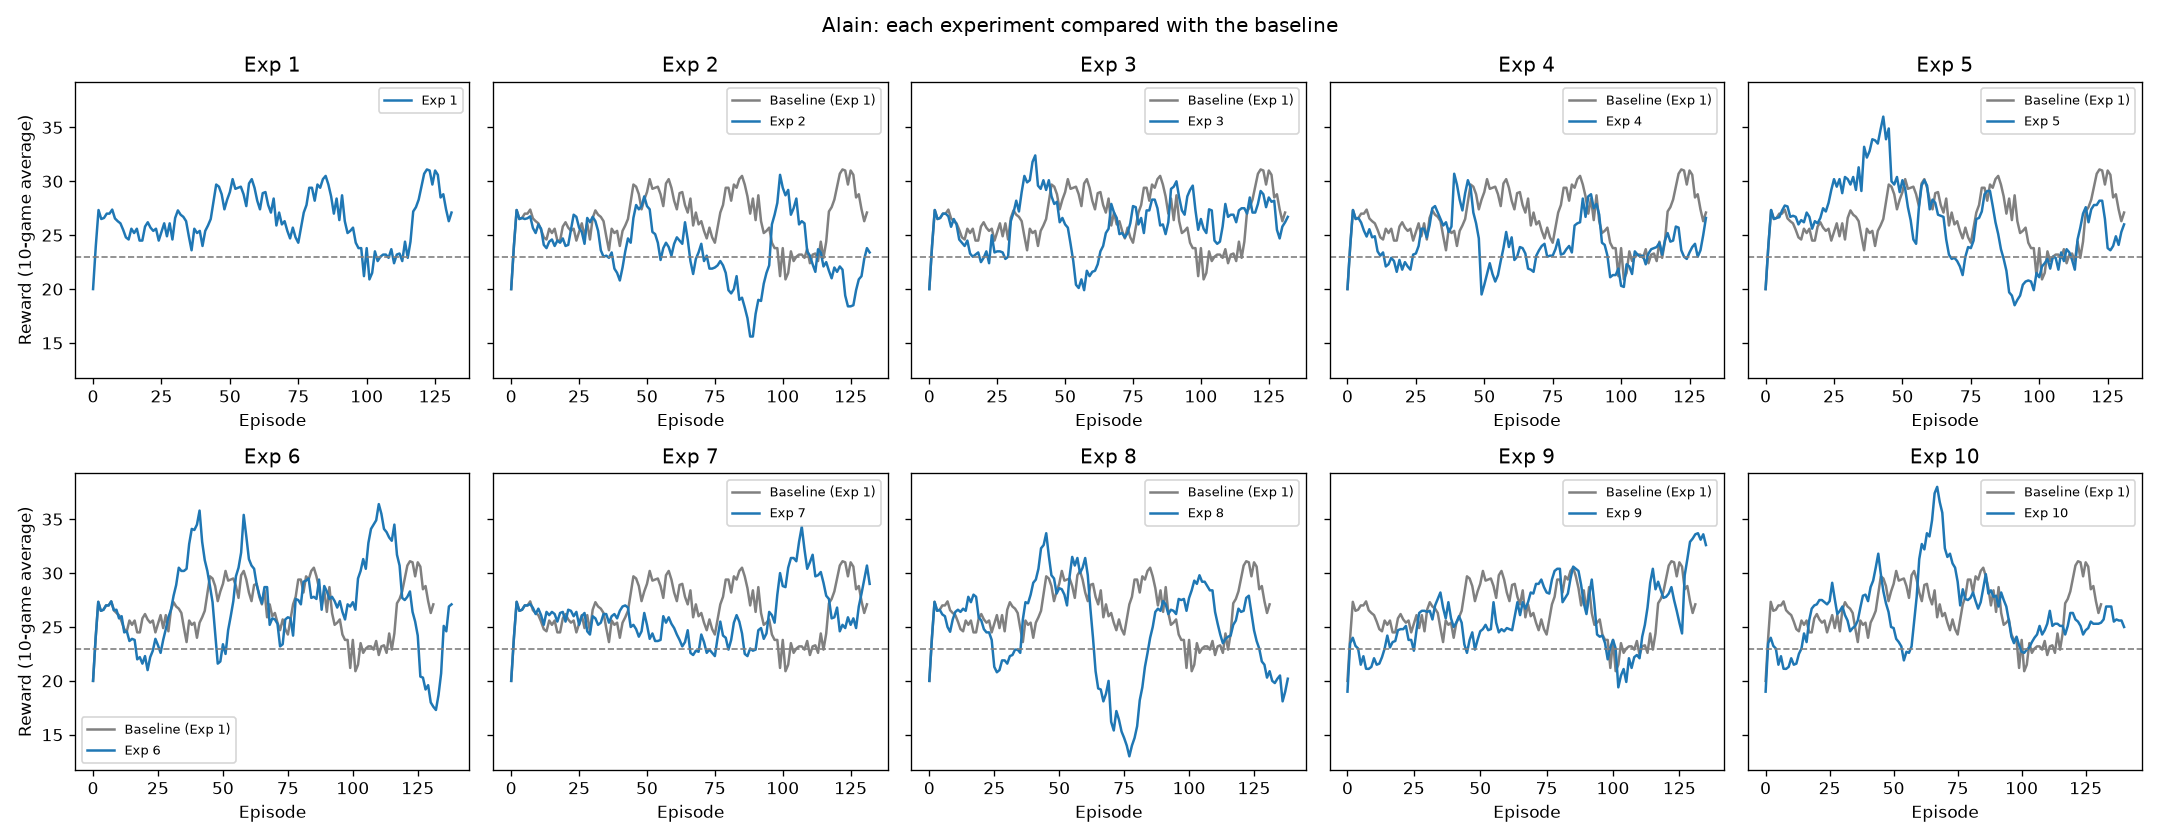

In [2]:
!uv run plot_results.py --member Alain
Image("Alain/reward_curves.png")

## 4. Pick the best experiment
`select_best.py` plays each saved model for 3 games with no random moves, like play.py, and ranks the experiments by that score. Ties are broken by the training average once epsilon reached its minimum. The best model is copied to `Alain/best_model/dqn_model.pth`.

In [2]:
!uv run select_best.py --member Alain

A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
  exp10: plays 30.0 | training average 25.2
  exp05: plays 30.0 | training average 24.6
  exp02: plays 30.0 | training average 22.8
  exp06: plays 6.0 | training average 27.9
  exp01: plays 0.0 | training average 26.7
  exp09: plays 0.0 | training average 26.4
  exp07: plays 0.0 | training average 26.3
  exp03: plays 0.0 | training average 26.1
  exp04: plays 0.0 | training average 24.0
  exp08: plays 0.0 | training average 23.7

Best for Alain: exp10 (plays 30.0, training average 25.2)
Model copied to Alain/best_model/dqn_model.pth


Exp 10 ranks first: it is one of three models that score 30 when playing, and it had the highest training average of the three. Below, it plays 10 games, and its plot shows the rewards, episode length and number of steps.

A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Game 1: reward 30 in 2161 steps
Game 2: reward 30 in 2161 steps
Game 3: reward 30 in 2160 steps
Game 4: reward 30 in 2162 steps
Game 5: reward 30 in 2153 steps
Game 6: reward 30 in 2159 steps
Game 7: reward 30 in 2153 steps
Game 8: reward 30 in 2156 steps
Game 9: reward 30 in 2157 steps
Game 10: reward 30 in 2158 steps
Buttons pressed: NOOP 42%, UPFIRE 23%, FIRE 22%
Saved plot to Alain/exp10/training_plot.png


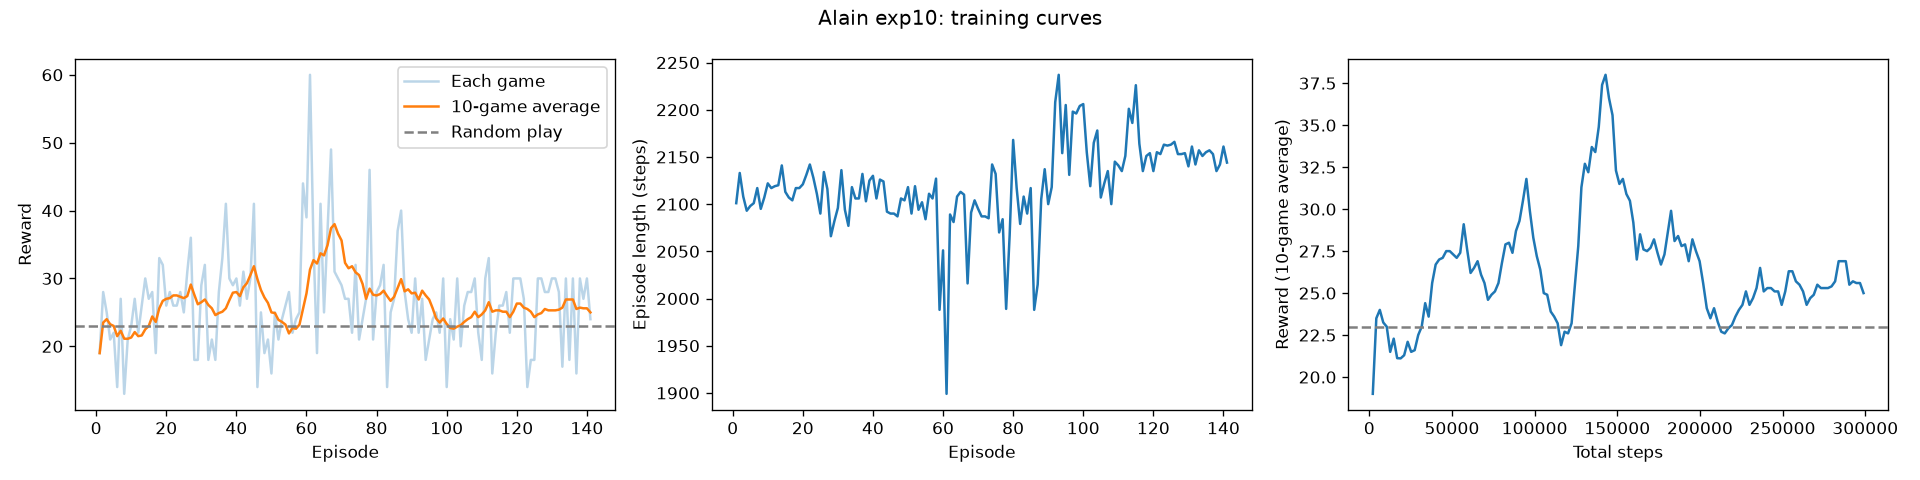

In [3]:
BEST = 10  # the experiment number select_best.py printed
!uv run greedy_check.py --member Alain --exp {BEST} --games 10
!uv run plot_results.py --member Alain --exp {BEST}
Image(f"Alain/exp{BEST:02d}/training_plot.png")

In [4]:
!zip -qr /kaggle/working/Alain_final_results.zip Alain